In [ ]:
import pandas as pd
import numpy as np

print("Libraries imported")

Libraries imported


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Cardiovascular_Disease_Dataset.csv to Cardiovascular_Disease_Dataset.csv


In [ ]:
file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
print("Dataset Shape:", df.shape)

Dataset Shape: (1000, 14)


In [ ]:
print(df.columns.tolist())

['patientid', 'age', 'gender', 'chestpain', 'restingBP', 'serumcholestrol', 'fastingbloodsugar', 'restingrelectro', 'maxheartrate', 'exerciseangia', 'oldpeak', 'slope', 'noofmajorvessels', 'target']


In [ ]:
df.head()

,patientid,age,gender,chestpain,restingBP,serumcholestrol,fastingbloodsugar,restingrelectro,maxheartrate,exerciseangia,oldpeak,slope,noofmajorvessels,target
0,103368,53,1,2,171,0,0,1,147,0,5.3,3,3,1
1,119250,40,1,0,94,229,0,1,115,0,3.7,1,1,0
2,119372,49,1,2,133,142,0,0,202,1,5.0,1,0,0
3,132514,43,1,0,138,295,1,1,153,0,3.2,2,2,1
4,146211,31,1,1,199,0,0,2,136,0,5.3,3,2,1


In [ ]:

# CELL 4: DATA QUALITY ANALYSIS

print("Missing values in each column:")
display(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

print("\nExact duplicate rows:")
print(df.duplicated().sum())

print("\nTarget class distribution:")
display(df["target"].value_counts(dropna=False))

print("\nTarget class percentages:")
display(
    (df["target"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

Missing values in each column:


,0
patientid,0
age,0
gender,0
chestpain,0
restingBP,0
serumcholestrol,0
fastingbloodsugar,0
restingrelectro,0
maxheartrate,0
exerciseangia,0



Total missing values:
0

Exact duplicate rows:
0

Target class distribution:


,count
target,
1,580
0,420



Target class percentages:


,proportion
target,
1,58.0
0,42.0


In [ ]:
# Numerical columns for outlier analysis
numerical_cols = [
    "age",
    "restingBP",
    "serumcholestrol",
    "maxheartrate",
    "oldpeak"
]

# IQR method
outlier_summary = []

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_summary.append({
        "Feature": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers)
    })

outlier_df = pd.DataFrame(outlier_summary)

print("Outlier Detection Using IQR Method")
display(outlier_df)

Outlier Detection Using IQR Method


,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
0,age,34.00,64.25,30.25,-11.375,109.625,0
1,restingBP,129.00,181.00,52.00,51.000,259.000,0
2,serumcholestrol,235.75,404.25,168.50,-17.000,657.000,0
3,maxheartrate,119.75,175.00,55.25,36.875,257.875,0
4,oldpeak,1.30,4.10,2.80,-2.900,8.300,0


In [ ]:
# Check unique values and gender distribution

print("Gender distribution:")
print(df["gender"].value_counts(dropna=False))

print("\nUnique values in each feature:")
for col in df.columns:
    print(f"\n{col}:")
    print("Unique values:", df[col].nunique())
    print("Sample values:", df[col].unique()[:15])

print("\nStatistical summary:")
display(df.describe().T)

Gender distribution:
gender
1    765
0    235
Name: count, dtype: int64

Unique values in each feature:

patientid:
Unique values: 1000
Sample values: [103368 119250 119372 132514 146211 148462 168686 170498 188225 192523
 201030 208877 223295 226481 229445]

age:
Unique values: 61
Sample values: [53 40 49 43 31 24 79 52 62 61 59 58 27 32 42]

gender:
Unique values: 2
Sample values: [1 0]

chestpain:
Unique values: 4
Sample values: [2 0 1 3]

restingBP:
Unique values: 95
Sample values: [171  94 133 138 199 173 130 127 121 190 192 129  98 170 188]

serumcholestrol:
Unique values: 344
Sample values: [  0 229 142 295 240 345 357 181 529 409 135 209 354 350 247]

fastingbloodsugar:
Unique values: 2
Sample values: [0 1]

restingrelectro:
Unique values: 3
Sample values: [1 0 2]

maxheartrate:
Unique values: 129
Sample values: [147 115 202 153 136 161 157 192 138 150 151 117 170 134 110]

exerciseangia:
Unique values: 2
Sample values: [0 1]

oldpeak:
Unique values: 63
Sample values: [5.3 3.7 

,count,mean,std,min,25%,50%,75%,max
patientid,1000.0,5.048704e+06,2.895905e+06,103368.0,2536439.50,4952508.5,7681877.00,9990855.0
age,1000.0,4.924200e+01,1.786473e+01,20.0,34.00,49.0,64.25,80.0
gender,1000.0,7.650000e-01,4.242110e-01,0.0,1.00,1.0,1.00,1.0
chestpain,1000.0,9.800000e-01,9.531571e-01,0.0,0.00,1.0,2.00,3.0
restingBP,1000.0,1.517470e+02,2.996523e+01,94.0,129.00,147.0,181.00,200.0
serumcholestrol,1000.0,3.114470e+02,1.324438e+02,0.0,235.75,318.0,404.25,602.0
fastingbloodsugar,1000.0,2.960000e-01,4.567194e-01,0.0,0.00,0.0,1.00,1.0
restingrelectro,1000.0,7.480000e-01,7.701228e-01,0.0,0.00,1.0,1.00,2.0
maxheartrate,1000.0,1.454770e+02,3.419027e+01,71.0,119.75,146.0,175.00,202.0
exerciseangia,1000.0,4.980000e-01,5.002462e-01,0.0,0.00,0.0,1.00,1.0


In [ ]:
# Check suspicious cholesterol values
print("Records with serum cholesterol = 0:")
display(df[df["serumcholestrol"] == 0])

print(
    "Zero cholesterol records:",
    (df["serumcholestrol"] == 0).sum()
)

# Check the ranges of categorical / coded features
coded_cols = [
    "gender",
    "chestpain",
    "fastingbloodsugar",
    "restingrelectro",
    "exerciseangia",
    "slope",
    "noofmajorvessels",
    "target"
]

for col in coded_cols:
    print(f"{col}: {sorted(df[col].dropna().unique())}")

# Confirm patient ID uniqueness
print("\nUnique patient IDs:", df["patientid"].nunique())
print("Total records:", len(df))

Records with serum cholesterol = 0:


,patientid,age,gender,chestpain,restingBP,serumcholestrol,fastingbloodsugar,restingrelectro,maxheartrate,exerciseangia,oldpeak,slope,noofmajorvessels,target
0,103368,53,1,2,171,0,0,1,147,0,5.3,3,3,1
4,146211,31,1,1,199,0,0,2,136,0,5.3,3,2,1
5,148462,24,1,1,173,0,0,0,161,0,4.7,3,2,1
15,235344,32,1,2,188,0,0,0,134,1,4.5,2,3,1
27,407924,42,1,0,157,0,0,2,196,0,4.2,2,2,1
68,804105,61,1,2,132,0,0,1,172,0,1.1,3,3,1
71,849997,77,0,1,195,0,0,1,129,1,1.2,2,1,1
91,1044234,44,1,1,169,0,0,2,174,1,6.0,2,1,1
95,1084906,43,0,0,190,0,0,1,101,1,0.4,2,1,1
118,1281446,30,0,2,95,0,0,0,112,0,2.6,3,3,1


Zero cholesterol records: 53
gender: [np.int64(0), np.int64(1)]
chestpain: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
fastingbloodsugar: [np.int64(0), np.int64(1)]
restingrelectro: [np.int64(0), np.int64(1), np.int64(2)]
exerciseangia: [np.int64(0), np.int64(1)]
slope: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
noofmajorvessels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
target: [np.int64(0), np.int64(1)]

Unique patient IDs: 1000
Total records: 1000


In [ ]:


# Keep the original dataframe unchanged
df_clean = df.copy()

# Treat zero cholesterol values as invalid / missing
zero_count = (df_clean["serumcholestrol"] == 0).sum()

df_clean.loc[
    df_clean["serumcholestrol"] == 0,
    "serumcholestrol"
] = np.nan

print("Invalid zero cholesterol values:", zero_count)
print("Missing cholesterol values after correction:",
      df_clean["serumcholestrol"].isna().sum())

print("\nDataset shape:", df_clean.shape)
display(df_clean.head())

Invalid zero cholesterol values: 53
Missing cholesterol values after correction: 53

Dataset shape: (1000, 14)


,patientid,age,gender,chestpain,restingBP,serumcholestrol,fastingbloodsugar,restingrelectro,maxheartrate,exerciseangia,oldpeak,slope,noofmajorvessels,target
0,103368,53,1,2,171,NaN,0,1,147,0,5.3,3,3,1
1,119250,40,1,0,94,229.0,0,1,115,0,3.7,1,1,0
2,119372,49,1,2,133,142.0,0,0,202,1,5.0,1,0,0
3,132514,43,1,0,138,295.0,1,1,153,0,3.2,2,2,1
4,146211,31,1,1,199,NaN,0,2,136,0,5.3,3,2,1


In [ ]:

# Separate input features and target
X = df_clean.drop(columns=["target", "patientid"])
y = df_clean["target"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts().sort_index())

print("\nTarget percentages:")
print((y.value_counts(normalize=True).sort_index() * 100).round(2))

Input features shape: (1000, 12)
Target shape: (1000,)

Target distribution:
target
0    420
1    580
Name: count, dtype: int64

Target percentages:
target
0    42.0
1    58.0
Name: proportion, dtype: float64


In [ ]:

from sklearn.model_selection import train_test_split

# Separate features and target
X = df_clean.drop(columns=["target", "patientid"])
y = df_clean["target"]

# Split the dataset while preserving class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

Training features: (800, 12)
Testing features: (200, 12)

Training target distribution:
target
0    336
1    464
Name: count, dtype: int64

Testing target distribution:
target
0     84
1    116
Name: count, dtype: int64


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Continuous numerical features
numeric_features = [
    "age",
    "restingBP",
    "serumcholestrol",
    "maxheartrate",
    "oldpeak"
]

# Categorical / coded features
categorical_features = [
    "gender",
    "chestpain",
    "fastingbloodsugar",
    "restingrelectro",
    "exerciseangia",
    "slope",
    "noofmajorvessels"
]

# Numerical preprocessing
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [ ]:

# Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using the same fitted preprocessing
X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:",
      X_train_processed.shape)

print("Testing data after preprocessing:",
      X_test_processed.shape)

print("\nMissing values in original training features:",
      X_train.isna().sum().sum())

print("Missing values in original testing features:",
      X_test.isna().sum().sum())

print("\nPreprocessing completed successfully.")

Training data after preprocessing: (800, 26)
Testing data after preprocessing: (200, 26)

Missing values in original training features: 43
Missing values in original testing features: 10

Preprocessing completed successfully.


In [ ]:
#Train and Compare 5 ML Models

import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Five Machine Learning Models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    "SVM": SVC(
        kernel="rbf",
        class_weight="balanced"
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    )
}

results = []
trained_models = {}

# Train and evaluate each model
for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    # Train model
    pipeline.fit(X_train, y_train)

    # Predict on test data
    y_pred = pipeline.predict(X_test)

    # Calculate performance metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        )
    })

    trained_models[name] = pipeline

# Display comparison
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

print("MODEL PERFORMANCE COMPARISON")
display(results_df.round(4))

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.985,0.9829,0.9914,0.9871
1,Logistic Regression,0.975,0.9664,0.9914,0.9787
2,SVM,0.975,0.9744,0.9828,0.9785
3,Decision Tree,0.975,0.9744,0.9828,0.9785
4,KNN,0.955,0.9652,0.9569,0.9610


Random Forest Confusion Matrix:
[[ 82   2]
 [  1 115]]

Classification Report:
                  precision    recall  f1-score   support

No Heart Disease       0.99      0.98      0.98        84
   Heart Disease       0.98      0.99      0.99       116

        accuracy                           0.98       200
       macro avg       0.99      0.98      0.98       200
    weighted avg       0.99      0.98      0.98       200



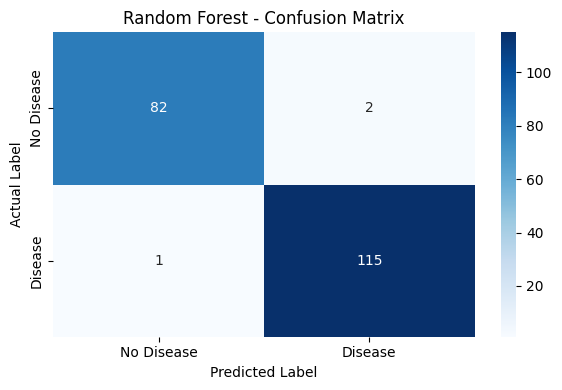

In [ ]:
#Random Forest Confusion Matrix

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Best model
best_model = trained_models["Random Forest"]

# Predictions on test data
y_pred_rf = best_model.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_rf)

print("Random Forest Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["No Heart Disease", "Heart Disease"]
))

# Visualize confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()


CLASSIFICATION REPORT: Logistic Regression
                  precision    recall  f1-score   support

No Heart Disease       0.99      0.95      0.97        84
   Heart Disease       0.97      0.99      0.98       116

        accuracy                           0.97       200
       macro avg       0.98      0.97      0.97       200
    weighted avg       0.98      0.97      0.97       200


CLASSIFICATION REPORT: Random Forest
                  precision    recall  f1-score   support

No Heart Disease       0.99      0.98      0.98        84
   Heart Disease       0.98      0.99      0.99       116

        accuracy                           0.98       200
       macro avg       0.99      0.98      0.98       200
    weighted avg       0.99      0.98      0.98       200


CLASSIFICATION REPORT: SVM
                  precision    recall  f1-score   support

No Heart Disease       0.98      0.96      0.97        84
   Heart Disease       0.97      0.98      0.98       116

        accu

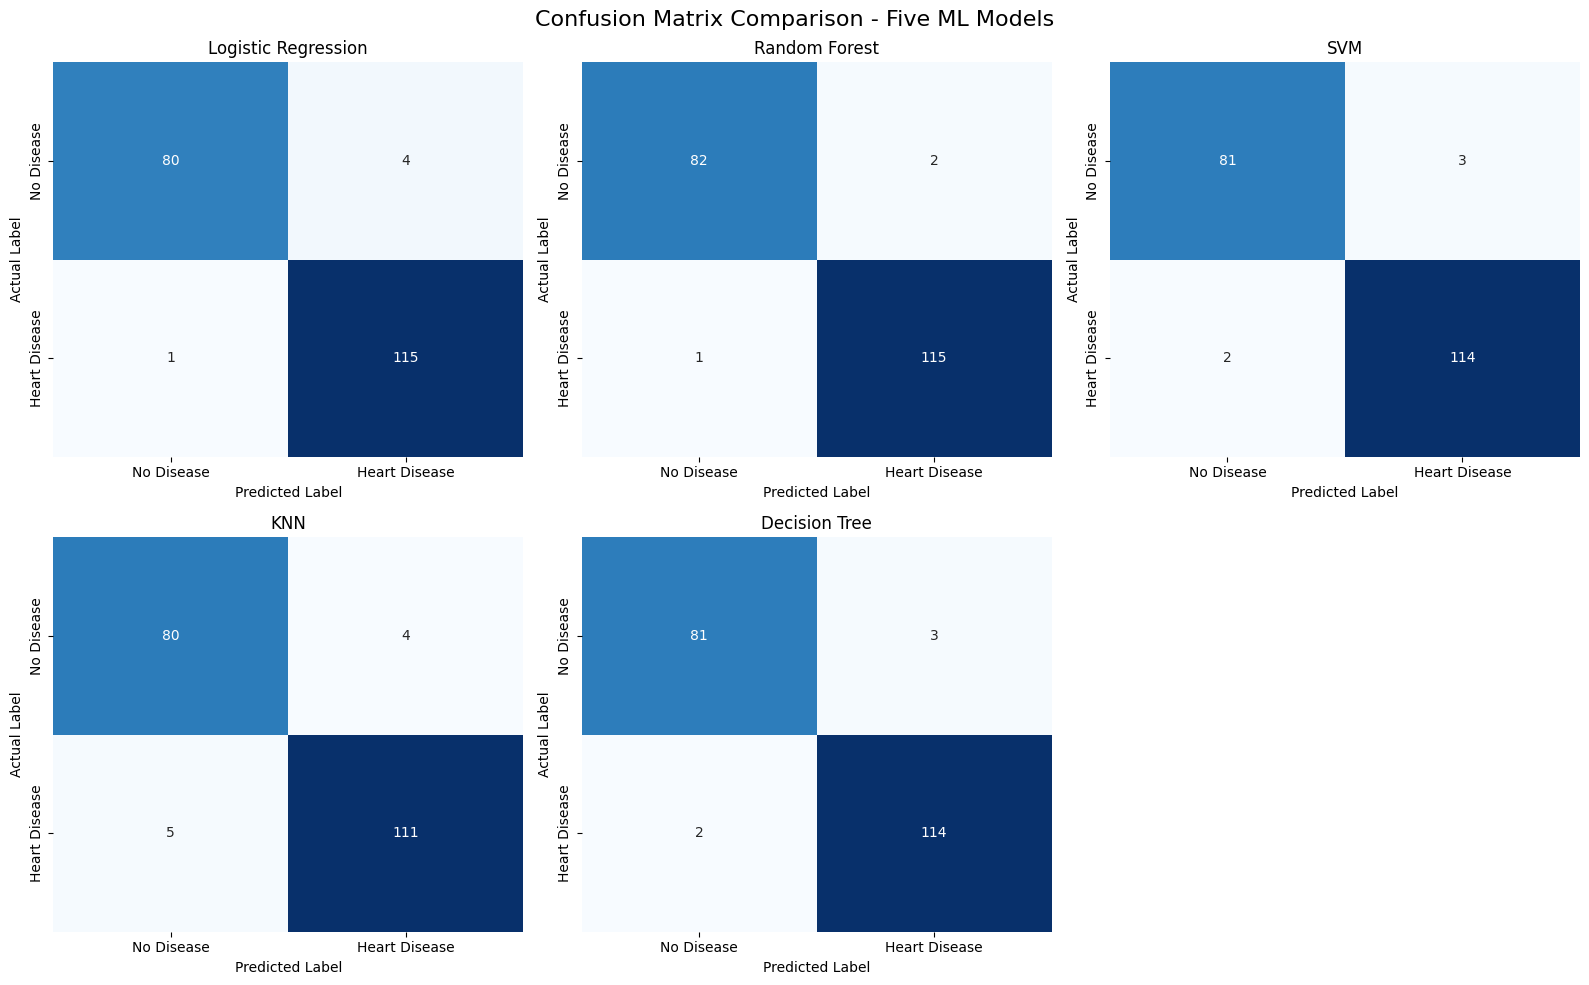

In [ ]:
# plots for all five models.
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from sklearn.metrics import confusion_matrix, classification_report

# All five trained models
model_names = [
    "Logistic Regression",
    "Random Forest",
    "SVM",
    "KNN",
    "Decision Tree"
]

# Create a single figure containing five confusion matrices
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, name in enumerate(model_names):

    # Get the already trained model pipeline
    model = trained_models[name]

    # Predict test data
    y_pred = model.predict(X_test)

    # Calculate confusion matrix
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    # Plot confusion matrix
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["No Disease", "Heart Disease"],
        yticklabels=["No Disease", "Heart Disease"],
        ax=axes[i]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("Actual Label")

    # Print classification report
    print("\n" + "=" * 60)
    print(f"CLASSIFICATION REPORT: {name}")
    print("=" * 60)

    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["No Heart Disease", "Heart Disease"],
        zero_division=0
    ))

# Remove the unused sixth subplot
fig.delaxes(axes[5])

plt.suptitle(
    "Confusion Matrix Comparison - Five ML Models",
    fontsize=16
)
plt.tight_layout()
plt.show()

In [ ]:
# explainable AI shap and lime

%pip install -q shap lime

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


SHAP analysis completed.
Explained records: 100
Features explained: 26


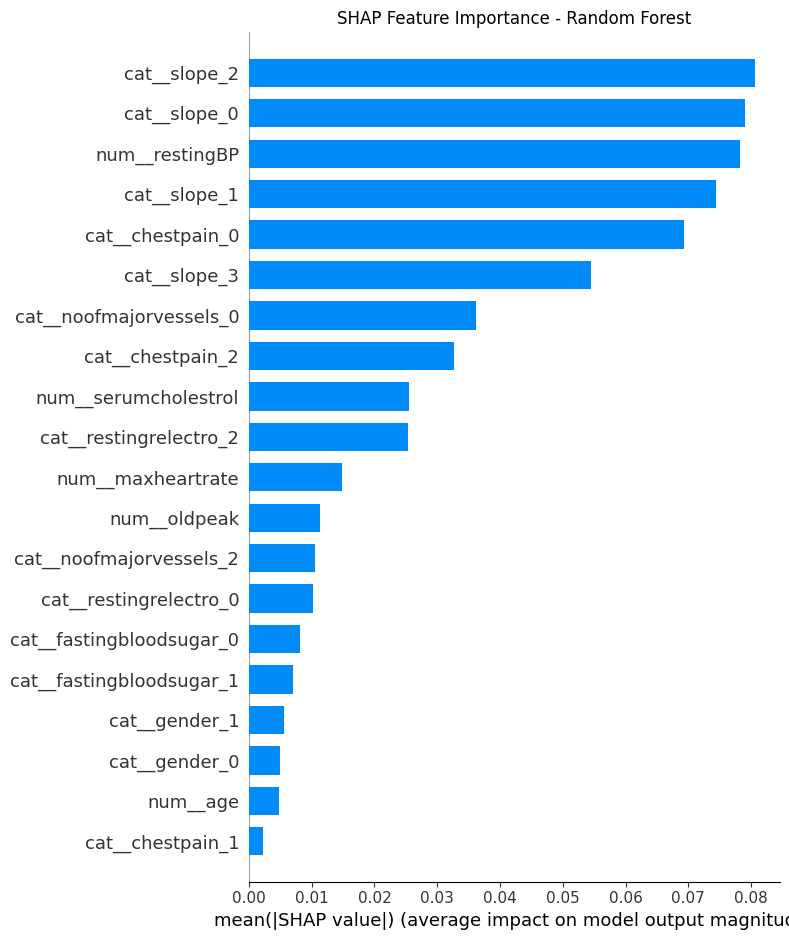

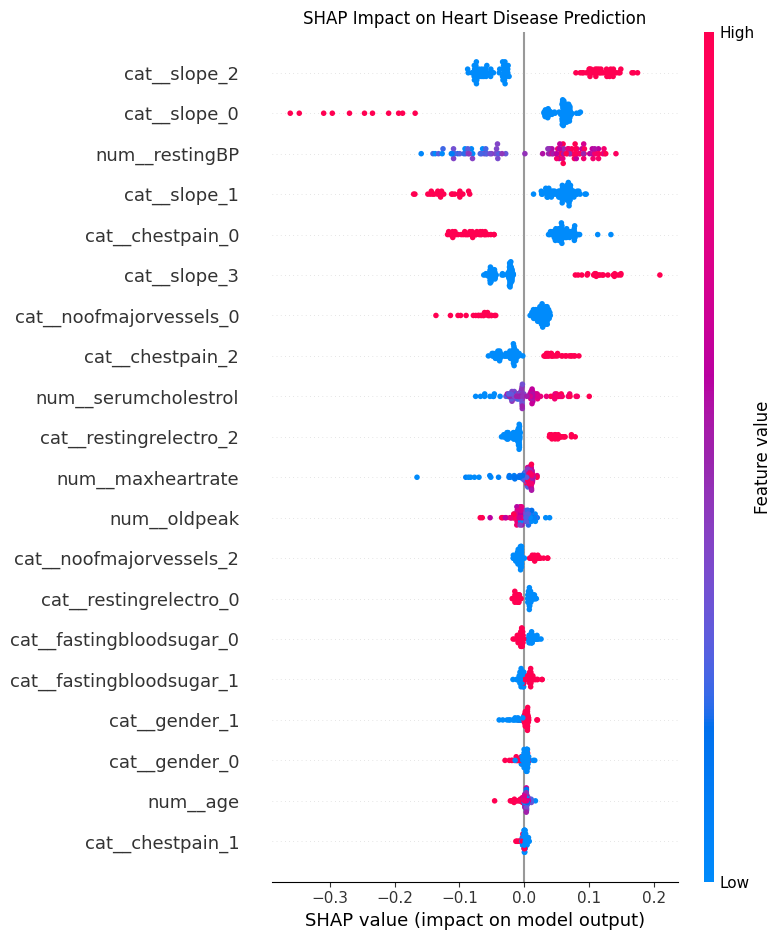

In [ ]:

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the trained Random Forest pipeline
best_model = trained_models["Random Forest"]

preprocessor_rf = best_model.named_steps["preprocessor"]
rf_classifier = best_model.named_steps["classifier"]

# Transform test data using the fitted preprocessing pipeline
X_test_transformed = preprocessor_rf.transform(X_test)

# Get feature names after encoding
feature_names = preprocessor_rf.get_feature_names_out()

# Convert transformed data to a DataFrame
if hasattr(X_test_transformed, "toarray"):
    X_shap = X_test_transformed.toarray()
else:
    X_shap = np.asarray(X_test_transformed)

X_shap_df = pd.DataFrame(
    X_shap,
    columns=feature_names,
    index=X_test.index
)

# Explain a sample of test records
X_explain = X_shap_df.iloc[:100]

# Create SHAP Tree Explainer
explainer = shap.TreeExplainer(rf_classifier)

# Calculate SHAP values
shap_values = explainer.shap_values(X_explain)

# Handle different SHAP output formats for binary classification
if isinstance(shap_values, list):
    # Older SHAP versions: class 1 = Heart Disease
    shap_positive = shap_values[1]
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    # Newer versions: samples, features, classes
    shap_positive = shap_values[:, :, 1]
else:
    # Some versions return a 2D array directly
    shap_positive = shap_values

print("SHAP analysis completed.")
print("Explained records:", X_explain.shape[0])
print("Features explained:", X_explain.shape[1])

# Plot 1: Global feature importance
shap.summary_plot(
    shap_positive,
    X_explain,
    plot_type="bar",
    show=False
)
plt.title("SHAP Feature Importance - Random Forest")
plt.tight_layout()
plt.show()

# Plot 2: Feature impact distribution
shap.summary_plot(
    shap_positive,
    X_explain,
    show=False
)
plt.title("SHAP Impact on Heart Disease Prediction")
plt.tight_layout()
plt.show()

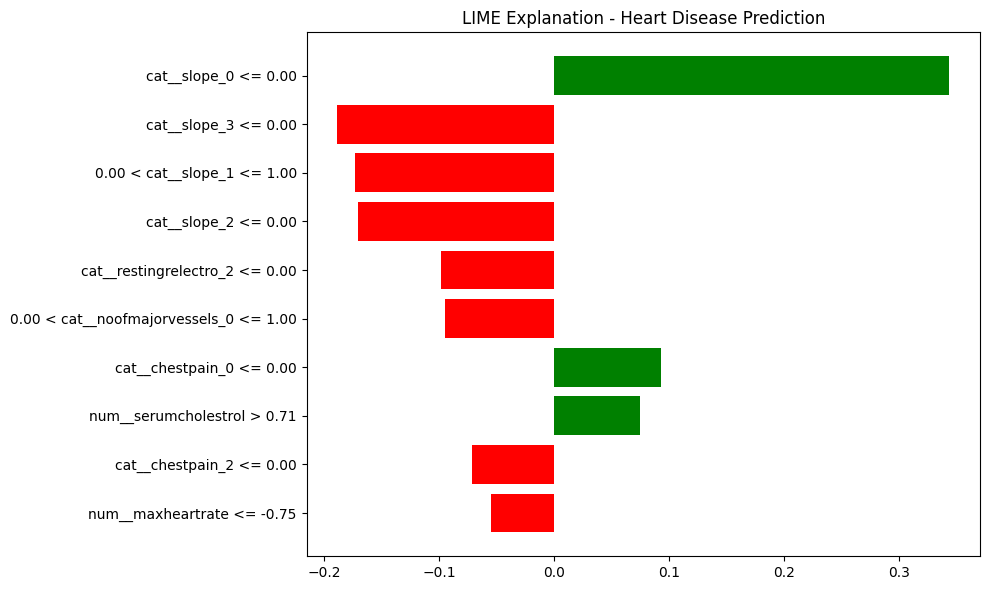

Actual class: 0
Predicted class: 0
Probability - No Heart Disease: 0.76
Probability - Heart Disease: 0.24


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lime.lime_tabular import LimeTabularExplainer

# Use the trained Random Forest pipeline
best_model = trained_models["Random Forest"]

# Get preprocessing and classifier separately
preprocessor_rf = best_model.named_steps["preprocessor"]
rf_classifier = best_model.named_steps["classifier"]

# Transform training and testing data
X_train_transformed = preprocessor_rf.transform(X_train)
X_test_transformed = preprocessor_rf.transform(X_test)

# Convert sparse matrices to dense arrays if necessary
if hasattr(X_train_transformed, "toarray"):
    X_train_lime = X_train_transformed.toarray()
else:
    X_train_lime = np.asarray(X_train_transformed)

if hasattr(X_test_transformed, "toarray"):
    X_test_lime = X_test_transformed.toarray()
else:
    X_test_lime = np.asarray(X_test_transformed)

# Get feature names after preprocessing
feature_names = preprocessor_rf.get_feature_names_out()

# Create LIME explainer
lime_explainer = LimeTabularExplainer(
    training_data=X_train_lime,
    feature_names=list(feature_names),
    class_names=["No Heart Disease", "Heart Disease"],
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

# Explain one test record
sample_index = 0
sample = X_test_lime[sample_index]

lime_exp = lime_explainer.explain_instance(
    data_row=sample,
    predict_fn=rf_classifier.predict_proba,
    num_features=10,
    labels=[1]
)

# Display explanation
fig = lime_exp.as_pyplot_figure(label=1)
fig.set_size_inches(10, 6)
plt.title("LIME Explanation - Heart Disease Prediction")
plt.tight_layout()
plt.show()

# Display the prediction for this record
prediction = best_model.predict(X_test.iloc[[sample_index]])[0]
probabilities = best_model.predict_proba(
    X_test.iloc[[sample_index]]
)[0]

print("Actual class:", y_test.iloc[sample_index])
print("Predicted class:", prediction)
print("Probability - No Heart Disease:", round(probabilities[0], 4))
print("Probability - Heart Disease:", round(probabilities[1], 4))

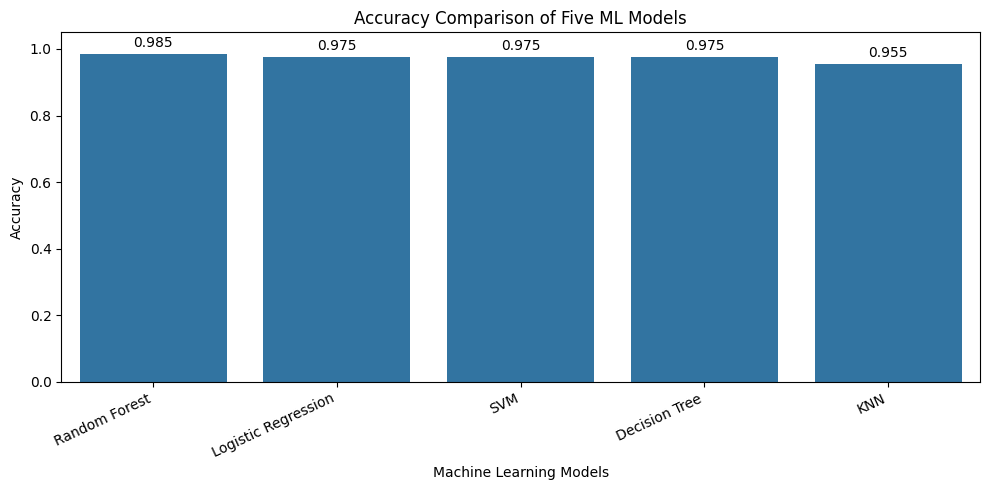

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# Sort models by accuracy
plot_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=plot_df,
    x="Model",
    y="Accuracy"
)

plt.title("Accuracy Comparison of Five ML Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3
    )

plt.tight_layout()
plt.show()

In [ ]:

# Display final performance table in percentage format
final_results = results_df.copy()

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

final_results[metric_columns] = (
    final_results[metric_columns] * 100
).round(2)

print("FINAL MODEL PERFORMANCE (Percentage)")
display(final_results)

FINAL MODEL PERFORMANCE (Percentage)


,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,98.5,98.29,99.14,98.71
1,Logistic Regression,97.5,96.64,99.14,97.87
2,SVM,97.5,97.44,98.28,97.85
3,Decision Tree,97.5,97.44,98.28,97.85
4,KNN,95.5,96.52,95.69,96.10


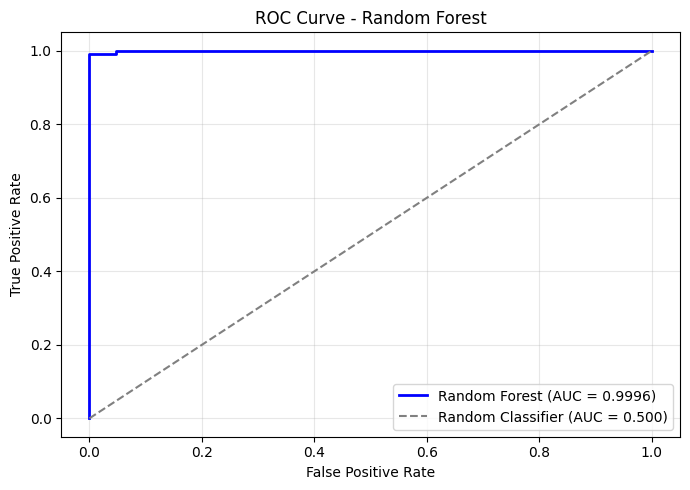

Random Forest ROC-AUC Score: 0.9996


In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Get the trained Random Forest model
rf_model = trained_models["Random Forest"]

# Predict probabilities for Heart Disease (class 1)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# Calculate ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_prob_rf)
auc_rf = roc_auc_score(y_test, y_prob_rf)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr, tpr,
    color="blue",
    linewidth=2,
    label=f"Random Forest (AUC = {auc_rf:.4f})"
)

# Random classifier reference line
plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier (AUC = 0.500)"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Random Forest ROC-AUC Score: {auc_rf:.4f}")

In [ ]:
# 1. Enter sample patient details
sample_patient = pd.DataFrame([{
    "age": 55,
    "gender": 1,
    "chestpain": 2,
    "restingBP": 140,
    "serumcholestrol": 240,
    "fastingbloodsugar": 1,
    "restingrelectro": 1,
    "maxheartrate": 150,
    "exerciseangia": 0,
    "oldpeak": 1.5,
    "slope": 2,
    "noofmajorvessels": 1
}])

# 2. Use the trained Random Forest model
rf_model = trained_models["Random Forest"]

# 3. Predict disease class
prediction = rf_model.predict(sample_patient)[0]

# 4. Calculate model probability
probabilities = rf_model.predict_proba(sample_patient)[0]
class_labels = list(rf_model.classes_)

heart_disease_index = class_labels.index(1)
risk_probability = probabilities[heart_disease_index] * 100

# 5. Display prediction
print("========== HEART DISEASE RISK PREDICTION ==========")
print("\nSample Patient Details:")
print(sample_patient.to_string(index=False))

print("\nPrediction Result:")

if prediction == 1:
    print("Predicted Class: Heart Disease")
else:
    print("Predicted Class: No Heart Disease")

print(f"Model-estimated probability for Heart Disease: {risk_probability:.2f}%")

========== HEART DISEASE RISK PREDICTION ==========

Sample Patient Details:
 age  gender  chestpain  restingBP  serumcholestrol  fastingbloodsugar  restingrelectro  maxheartrate  exerciseangia  oldpeak  slope  noofmajorvessels
  55       1          2        140              240                  1                1           150              0      1.5      2                 1

Prediction Result:
Predicted Class: Heart Disease
Model-estimated probability for Heart Disease: 98.00%


In [ ]:
trained_models["Random Forest"]

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'restingBP',
                                                   'serumcholestrol',
                                                   'maxheartrate', 'oldpeak']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['gender', 'chestpain',
                                                   'fastingbloodsugar',
                                                   'restingrelectro',
                                                   'exerciseangia', 'slope',
                                                   'noofmajorvessels'])])),
                ('classifier',
                 RandomForestClassifier(n_estimators=200, random_state=42))])

In [ ]:
import joblib

# Select the trained Random Forest pipeline
rf_model = trained_models["Random Forest"]

# Save the model as a file
joblib.dump(
    rf_model,
    "/content/heartcare_rf_pipeline.joblib"
)

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [ ]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.6.1


In [ ]:
import os

file_path = "/content/heartcare_rf_pipeline.joblib"

if os.path.exists(file_path):
    print("File exists!")
    print("File size:", round(os.path.getsize(file_path) / 1024, 2), "KB")
else:
    print("File not found. Please save the model again.")

File exists!
File size: 1721.25 KB


In [ ]:
from google.colab import files

files.download("/content/heartcare_rf_pipeline.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
categorical_columns = [
    "gender",
    "chestpain",
    "fastingbloodsugar",
    "restingrelectro",
    "exerciseangia",
    "slope",
    "noofmajorvessels"
]

for col in categorical_columns:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False).sort_index())


gender
gender
0    235
1    765
Name: count, dtype: int64

chestpain
chestpain
0    420
1    224
2    312
3     44
Name: count, dtype: int64

fastingbloodsugar
fastingbloodsugar
0    704
1    296
Name: count, dtype: int64

restingrelectro
restingrelectro
0    454
1    344
2    202
Name: count, dtype: int64

exerciseangia
exerciseangia
0    502
1    498
Name: count, dtype: int64

slope
slope
0    180
1    299
2    322
3    199
Name: count, dtype: int64

noofmajorvessels
noofmajorvessels
0    275
1    344
2    265
3    116
Name: count, dtype: int64


In [ ]:
!streamlit run /content/app.py --server.port 8501

In [ ]:
!pip -q install pyngrok

In [ ]:
# CELL 1: IMPORT LIBRARIES AND MOUNT GOOGLE DRIVE

import os
import shutil
import time
import subprocess
import requests
import joblib
import pandas as pd
import sqlite3

from google.colab import drive, files
from getpass import getpass

print("All libraries imported successfully!")

# Mount Google Drive
drive.mount('/content/drive')

print("Google Drive mounted successfully!")

All libraries imported successfully!
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive mounted successfully!


In [ ]:
# CELL 2: UPLOAD TRAINED MODEL

uploaded = files.upload()

model_filename = "heartcare_rf_pipeline.joblib"

if model_filename in uploaded:
    with open("/content/" + model_filename, "wb") as f:
        f.write(uploaded[model_filename])

    print("Random Forest model uploaded successfully!")

else:
    print("Please upload the file named heartcare_rf_pipeline.joblib")

Saving heartcare_rf_pipeline.joblib to heartcare_rf_pipeline.joblib
Random Forest model uploaded successfully!


In [ ]:
# CELL 3: INSTALL REQUIRED PACKAGES

!pip -q install streamlit pyngrok

print("Required packages installed successfully!")

Required packages installed successfully!


In [ ]:
# CELL 4: CREATE DATABASE FOLDER

DB_DIR = "/content/drive/MyDrive/HeartCareAI"

os.makedirs(DB_DIR, exist_ok=True)

print("Database folder created successfully!")
print("Database folder:", DB_DIR)

Database folder created successfully!
Database folder: /content/drive/MyDrive/HeartCareAI


In [ ]:
from pyngrok import ngrok

# Check existing ngrok configuration
print("Existing ngrok configuration is available!")

# Start ngrok tunnel
public_url = ngrok.connect(8501)

print("Your public URL:", public_url)

Existing ngrok configuration is available!
Your public URL: NgrokTunnel: "https://spongy-untrained-margin.ngrok-free.dev" -> "http://localhost:8501"


In [ ]:
%%writefile /content/app.py
import os, sqlite3, uuid
from datetime import datetime
import joblib
import pandas as pd
import streamlit as st

st.set_page_config(page_title="HeartCare AI | Heart Health Dashboard", page_icon="❤️", layout="wide")

MODEL_PATH = "/content/heartcare_rf_pipeline.joblib"
DB_DIR = "/content/drive/MyDrive/HeartCareAI"
DB_PATH = os.path.join(DB_DIR, "heartcare_patients.db")
FEATURES = ["age","gender","chestpain","restingBP","serumcholestrol","fastingbloodsugar",
            "restingrelectro","maxheartrate","exerciseangia","oldpeak","slope","noofmajorvessels"]

# ---------------- DATABASE ----------------
def connect_db():
    if not os.path.isdir("/content/drive/MyDrive"):
        raise RuntimeError("Google Drive is not mounted. Run drive.mount('/content/drive') first.")
    os.makedirs(DB_DIR, exist_ok=True)
    return sqlite3.connect(DB_PATH, timeout=30)

def init_db():
    con = connect_db()
    con.execute("""
    CREATE TABLE IF NOT EXISTS patient_records (
      record_id INTEGER PRIMARY KEY AUTOINCREMENT,
      patient_id TEXT UNIQUE NOT NULL,
      created_at TEXT NOT NULL,
      updated_at TEXT,
      age INTEGER, gender INTEGER, chestpain INTEGER, restingBP INTEGER,
      serumcholestrol INTEGER, fastingbloodsugar INTEGER, restingrelectro INTEGER,
      maxheartrate INTEGER, exerciseangia INTEGER, oldpeak REAL, slope INTEGER,
      noofmajorvessels INTEGER, prediction INTEGER, predicted_probability REAL
    )""")
    cols = {r[1] for r in con.execute("PRAGMA table_info(patient_records)")}
    if "updated_at" not in cols:
        con.execute("ALTER TABLE patient_records ADD COLUMN updated_at TEXT")
        con.execute("UPDATE patient_records SET updated_at=created_at WHERE updated_at IS NULL")
    con.commit()
    con.close()

def save_record(d):
    con = connect_db()
    con.execute("""
    INSERT INTO patient_records
    (patient_id,created_at,updated_at,age,gender,chestpain,restingBP,serumcholestrol,
     fastingbloodsugar,restingrelectro,maxheartrate,exerciseangia,oldpeak,slope,
     noofmajorvessels,prediction,predicted_probability)
    VALUES (?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?)
    """, tuple(d[k] for k in [
        "patient_id","created_at","updated_at","age","gender","chestpain","restingBP",
        "serumcholestrol","fastingbloodsugar","restingrelectro","maxheartrate",
        "exerciseangia","oldpeak","slope","noofmajorvessels","prediction","predicted_probability"]))
    con.commit()
    con.close()

def read_records(patient_id=None):
    con = connect_db()
    if patient_id:
        df = pd.read_sql_query(
            "SELECT * FROM patient_records WHERE patient_id=? ORDER BY record_id DESC",
            con, params=(patient_id.strip().upper(),))
    else:
        df = pd.read_sql_query("SELECT * FROM patient_records ORDER BY record_id DESC", con)
    con.close()
    return df

def update_record(d):
    con = connect_db()
    cur = con.execute("""
    UPDATE patient_records SET updated_at=?, age=?, gender=?, chestpain=?, restingBP=?,
      serumcholestrol=?, fastingbloodsugar=?, restingrelectro=?, maxheartrate=?,
      exerciseangia=?, oldpeak=?, slope=?, noofmajorvessels=?, prediction=?,
      predicted_probability=? WHERE patient_id=?
    """, tuple(d[k] for k in [
        "updated_at","age","gender","chestpain","restingBP","serumcholestrol",
        "fastingbloodsugar","restingrelectro","maxheartrate","exerciseangia",
        "oldpeak","slope","noofmajorvessels","prediction","predicted_probability","patient_id"]))
    con.commit()
    n = cur.rowcount
    con.close()
    return n

def delete_record(pid):
    con = connect_db()
    cur = con.execute("DELETE FROM patient_records WHERE patient_id=?", (pid.strip().upper(),))
    con.commit()
    n = cur.rowcount
    con.close()
    return n

# ---------------- MODEL AND STARTUP ----------------
@st.cache_resource
def load_model():
    if not os.path.exists(MODEL_PATH):
        raise FileNotFoundError(f"Model file not found: {MODEL_PATH}")
    return joblib.load(MODEL_PATH)

try:
    model = load_model()
    init_db()
except Exception as e:
    st.error(f"Startup error: {e}")
    st.info("In Colab, mount Google Drive first: from google.colab import drive; drive.mount('/content/drive')")
    st.stop()

if "last_result" not in st.session_state:
    st.session_state.last_result = None
if "navigation" not in st.session_state:
    st.session_state.navigation = "Home"
if "current_patient_id" not in st.session_state:
    st.session_state.current_patient_id = "Not generated yet"

# ---------------- STYLE ----------------
st.markdown("""
<style>
.stApp{background:#f5f8fc}
[data-testid="stSidebar"]{background:#102a43}
[data-testid="stSidebar"] *{color:white!important}
.hero{background:linear-gradient(120deg,#12304a,#176b87);padding:32px;border-radius:18px;color:white;margin-bottom:24px}
.hero h1{color:white;font-size:36px}.hero p{color:#e5f3fa;font-size:17px}
.main-title{font-size:35px;font-weight:800;color:#12304a}
.subtitle{font-size:16px;color:#64748b}
.info-card{background:white;padding:22px;border-radius:14px;border:1px solid #e3edf5;min-height:140px}
.info-card h3{color:#176b87}.info-card p{color:#526477}
.result-card{background:white;border-radius:16px;padding:25px;border:1px solid #e3edf5;text-align:center}
div.stButton>button,div.stFormSubmitButton>button{background:#087e8b;color:white;border-radius:9px;border:0;font-weight:600}
.footer{text-align:center;color:#718096;padding:24px;font-size:13px}
</style>
""", unsafe_allow_html=True)

# ---------------- HELPERS ----------------
def parse_int(raw, label, low, high):
    try:
        value = int(str(raw).strip())
    except (ValueError, TypeError):
        return None, f"{label} must be a valid whole number."
    if not low <= value <= high:
        return None, f"{label} must be between {low} and {high}."
    return value, None

def predict(dataframe):
    pred = int(model.predict(dataframe)[0])
    probs = model.predict_proba(dataframe)[0]
    classes = list(model.classes_)
    return pred, float(probs[classes.index(pred)] * 100)

def display_result(result):
    st.divider()
    st.markdown("## Prediction Result")
    st.write(f"**Patient ID:** {result['patient_id']}")
    st.write(f"**Date and time:** {result['created_at']}")
    if result["prediction"] == 1:
        st.error("❤️ Model Prediction: Heart Disease")
    else:
        st.success("💚 Model Prediction: No Heart Disease")
    st.markdown(f"""
    <div class="result-card">
      <h3>Predicted Class Probability</h3>
      <h1 style="color:#087e8b;font-size:45px">{result['probability']:.2f}%</h1>
      <p>Probability corresponding to the predicted class</p>
    </div>""", unsafe_allow_html=True)
    st.progress(min(max(result["probability"]/100, 0), 1))
    st.markdown("### Patient Input Summary")
    st.dataframe(result["input"], use_container_width=True, hide_index=True)
    st.warning("This academic model output is not a medical diagnosis. Consult a qualified healthcare professional.")

# ---------------- SIDEBAR ----------------
st.sidebar.markdown("# ❤️ HeartCare AI")
st.sidebar.caption("Heart Health Prediction System")
st.sidebar.divider()
pages = ["Home","Predictor","Patient Records","Understanding Health Parameters","Heart Health Tips"]
page = st.sidebar.radio("Navigation", pages, key="navigation")
st.sidebar.divider()
st.sidebar.markdown("### Patient Session")
st.sidebar.write(f"Latest Patient ID: {st.session_state.current_patient_id}")

# ---------------- HOME ----------------
if page == "Home":
    st.markdown("""
    <div class="hero"><h1>❤️ HeartCare AI</h1>
    <p>Intelligent Heart Health Dashboard</p>
    <p>A Machine Learning based system designed to predict heart disease using patient health parameters.</p></div>
    """, unsafe_allow_html=True)
    st.markdown("## Welcome to HeartCare AI")
    c1,c2 = st.columns([1.5,1])
    with c1:
        st.markdown("""
        ### About HeartCare AI
        ❤️
        HeartCare AI uses a trained Machine Learning model to analyze selected patient health information.

        The system accepts:
        - Age and gender
        - Chest pain information
        - Blood pressure and serum cholesterol
        - Resting ECG and maximum heart rate
        - Exercise-related information

        The application displays the model's predicted class and its probability.
        """)
        def open_predictor_page():
            st.session_state.last_result = None
            st.session_state.navigation = "Predictor"

        st.button(
            "Start Heart Disease Prediction",
            use_container_width=True,
            on_click=open_predictor_page,
        )
    with c2:
        st.image("https://images.unsplash.com/photo-1559839734-2b71ea197ec2?w=900",
                 caption="Healthcare professional", use_container_width=True)
    st.divider()
    st.markdown("## Dashboard Features")
    a,b,c = st.columns(3)
    with a:
        st.markdown('<div class="info-card"><h3>🧠 Machine Learning</h3><p>Uses a trained Random Forest model.</p></div>', unsafe_allow_html=True)
    with b:
        st.markdown('<div class="info-card"><h3>📊 Health Parameters</h3><p>Analyzes patient health and medical test information.</p></div>', unsafe_allow_html=True)
    with c:
        st.markdown('<div class="info-card"><h3>📈 Prediction Results</h3><p>Displays predicted class and its probability.</p></div>', unsafe_allow_html=True)
    st.info("This application is an academic project. Its predictions are not a medical diagnosis.")

# ---------------- PREDICTOR ----------------
elif page == "Predictor":
    st.markdown('<p class="main-title">❤️ Heart Disease Predictor</p>', unsafe_allow_html=True)
    st.markdown('<p class="subtitle">Enter patient information and medical test values below.</p>', unsafe_allow_html=True)
    st.info("Use values from the patient's medical report. Do not guess technical test values.")

    with st.form("prediction_form"):
        st.markdown("### 👤 Patient Information")
        c1,c2 = st.columns(2)
        with c1:
            age = st.number_input("Age (years)", 1, 120, 45)
        with c2:
            gender_label = st.selectbox("Gender", ["Female (0)","Male (1)"])
        st.divider()
        st.markdown("### ❤️ Heart and Blood Test Information")
        c1,c2 = st.columns(2)
        with c1:
            chest_label = st.selectbox("Chest Pain Type", [
                "0 (Typical angina)","1 (Atypical angina)",
                "2 (Non-anginal chest pain)","3 (Asymptomatic)"])
            bp_text = st.text_input("Resting Blood Pressure (mmHg)", "120")
            chol_text = st.text_input("Serum Cholesterol (mg/dL)", "200")
            fbs_label = st.selectbox("Fasting Blood Sugar", ["0 (≤120 mg/dL)","1 (>120 mg/dL)"])
            ecg_label = st.selectbox("Resting ECG", [
                "0 (Normal ECG)","1 (ST-T wave abnormality)","2 (Possible/definite LVH)"])
        with c2:
            hr_text = st.text_input("Maximum Heart Rate (bpm)", "150")
            angina_label = st.selectbox("Exercise-Induced Angina", ["0 (No)","1 (Yes)"])
            oldpeak = st.number_input("Oldpeak", 0.0, 6.2, 1.0, 0.1, format="%.1f")
            slope_label = st.selectbox("Slope", [
                "0 (Unspecified dataset category)","1 (Upsloping)","2 (Flat)","3 (Downsloping)"])
            vessels_label = st.selectbox("Number of Major Vessels", [
                "0 (0 major vessels)","1 (1 major vessel)","2 (2 major vessels)","3 (3 major vessels)"])
        submitted = st.form_submit_button("🔍 Predict Heart Disease", use_container_width=True)

    if submitted:
        errors = []
        bp,err = parse_int(bp_text,"Resting Blood Pressure",94,200)
        if err: errors.append(err)
        chol,err = parse_int(chol_text,"Serum Cholesterol",126,602)
        if err: errors.append(err)
        hr,err = parse_int(hr_text,"Maximum Heart Rate",71,202)
        if err: errors.append(err)
        if errors:
            for msg in errors: st.error(msg)
        else:
            vals = [
                int(age), 0 if gender_label.startswith("Female") else 1,
                int(chest_label.split()[0]), bp, chol, int(fbs_label.split()[0]),
                int(ecg_label.split()[0]), hr, int(angina_label.split()[0]),
                float(oldpeak), int(slope_label.split()[0]), int(vessels_label.split()[0])
            ]
            X = pd.DataFrame([vals], columns=FEATURES)
            try:
                pred, prob = predict(X)
                now = datetime.now().astimezone().isoformat(timespec="seconds")
                pid = "HC-" + uuid.uuid4().hex[:8].upper()
                record = dict(zip(FEATURES, vals))
                record.update({
                    "patient_id":pid, "created_at":now, "updated_at":now,
                    "prediction":pred, "predicted_probability":prob
                })
                save_record(record)
                st.session_state.current_patient_id = pid
                st.session_state.last_result = {
                    "patient_id":pid,"created_at":now,"prediction":pred,
                    "probability":prob,"input":X.copy()
                }
                st.success(f"Patient record saved successfully! Patient ID: {pid}")
            except Exception as e:
                st.error(f"Prediction or database save failed: {e}")
    if st.session_state.last_result is not None:
        display_result(st.session_state.last_result)

# ---------------- PATIENT RECORDS ----------------
elif page == "Patient Records":
    st.markdown('<p class="main-title">🗂️ Patient Records</p>', unsafe_allow_html=True)
    st.markdown('<p class="subtitle">View, search, update, download and delete saved patient information.</p>', unsafe_allow_html=True)
    try:
        records = read_records()
    except Exception as e:
        st.error(f"Could not read patient records: {e}")
        st.stop()
    st.metric("Total Saved Patient Records", len(records))
    st.divider()

    st.markdown("### 🔍 Search Patient")
    search_id = st.text_input("Enter exact Patient ID", placeholder="Example: HC-A1B2C3D4", key="search_id")
    shown = read_records(search_id) if search_id.strip() else records
    if shown.empty:
        st.info("No patient records found.")
    else:
        st.dataframe(shown, use_container_width=True, hide_index=True)
        st.download_button("⬇️ Download displayed records as CSV",
            shown.to_csv(index=False).encode("utf-8"),
            "HeartCare_Patient_Records.csv","text/csv",use_container_width=True)

    st.divider()
    st.markdown("### ✏️ Update Patient Details")
    all_records = read_records()
    if all_records.empty:
        st.info("No patient records are available to update.")
    else:
        ids = all_records["patient_id"].tolist()
        selected_id = st.selectbox("Select Patient ID to update", ids, key="update_id")
        old = all_records[all_records.patient_id == selected_id].iloc[0]

        with st.form("update_patient_form"):
            st.caption("Edit details below. The same Patient ID will be retained and the model prediction will be recalculated.")
            c1,c2 = st.columns(2)
            with c1:
                e_age = st.number_input("Age (years)",1,120,int(old.age),key="e_age")
                e_gender = st.selectbox("Gender",["Female (0)","Male (1)"],int(old.gender),key="e_gender")
                e_chest = st.selectbox("Chest Pain Type",[
                    "0 (Typical angina)","1 (Atypical angina)","2 (Non-anginal chest pain)","3 (Asymptomatic)"],
                    int(old.chestpain),key="e_chest")
                e_bp = st.text_input("Resting Blood Pressure (mmHg)",str(int(old.restingBP)),key="e_bp")
                e_chol = st.text_input("Serum Cholesterol (mg/dL)",str(int(old.serumcholestrol)),key="e_chol")
                e_fbs = st.selectbox("Fasting Blood Sugar",["0 (≤120 mg/dL)","1 (>120 mg/dL)"],
                    int(old.fastingbloodsugar),key="e_fbs")
            with c2:
                e_ecg = st.selectbox("Resting ECG",[
                    "0 (Normal ECG)","1 (ST-T wave abnormality)","2 (Possible/definite LVH)"],
                    int(old.restingrelectro),key="e_ecg")
                e_hr = st.text_input("Maximum Heart Rate (bpm)",str(int(old.maxheartrate)),key="e_hr")
                e_angina = st.selectbox("Exercise-Induced Angina",["0 (No)","1 (Yes)"],
                    int(old.exerciseangia),key="e_angina")
                e_oldpeak = st.number_input("Oldpeak",0.0,6.2,float(old.oldpeak),0.1,key="e_oldpeak")
                e_slope = st.selectbox("Slope",[
                    "0 (Unspecified dataset category)","1 (Upsloping)","2 (Flat)","3 (Downsloping)"],
                    int(old.slope),key="e_slope")
                e_vessels = st.selectbox("Number of Major Vessels",[
                    "0 (0 major vessels)","1 (1 major vessel)","2 (2 major vessels)","3 (3 major vessels)"],
                    int(old.noofmajorvessels),key="e_vessels")
            do_update = st.form_submit_button("💾 Update Patient Details",use_container_width=True)

        if do_update:
            errors = []
            new_bp,err = parse_int(e_bp,"Resting Blood Pressure",94,200)
            if err: errors.append(err)
            new_chol,err = parse_int(e_chol,"Serum Cholesterol",126,602)
            if err: errors.append(err)
            new_hr,err = parse_int(e_hr,"Maximum Heart Rate",71,202)
            if err: errors.append(err)
            if errors:
                for msg in errors: st.error(msg)
            else:
                vals = [
                    int(e_age),0 if e_gender.startswith("Female") else 1,
                    int(e_chest.split()[0]),new_bp,new_chol,int(e_fbs.split()[0]),
                    int(e_ecg.split()[0]),new_hr,int(e_angina.split()[0]),
                    float(e_oldpeak),int(e_slope.split()[0]),int(e_vessels.split()[0])
                ]
                X = pd.DataFrame([vals],columns=FEATURES)
                try:
                    pred,prob = predict(X)
                    update_data = dict(zip(FEATURES,vals))
                    update_data.update({
                        "patient_id":selected_id,
                        "updated_at":datetime.now().astimezone().isoformat(timespec="seconds"),
                        "prediction":pred,"predicted_probability":prob
                    })
                    changed = update_record(update_data)
                    if changed:
                        st.session_state.last_result = None
                        st.success(f"Patient {selected_id} updated. Prediction recalculated.")
                        if pred == 1: st.error("Updated prediction: Heart Disease")
                        else: st.success("Updated prediction: No Heart Disease")
                        st.write(f"Updated predicted-class probability: {prob:.2f}%")
                        st.rerun()
                    else:
                        st.error("No matching record was updated. Refresh and try again.")
                except Exception as e:
                    st.error(f"Unable to update patient record: {e}")

    st.divider()
    st.markdown("### 🗑️ Delete Patient Record")
    delete_id = st.text_input("Enter exact Patient ID to delete",key="delete_id")
    confirm = st.checkbox("I confirm that I want to permanently delete this record.",key="confirm_delete")
    if st.button("Delete Patient Record"):
        if not delete_id.strip():
            st.error("Please enter a Patient ID.")
        elif not confirm:
            st.warning("Please confirm before deleting.")
        else:
            try:
                n = delete_record(delete_id)
                if n:
                    st.success("Patient record deleted successfully.")
                    st.rerun()
                else: st.warning("Patient ID not found.")
            except Exception as e: st.error(f"Unable to delete record: {e}")
    st.info("Update changes the existing row under the same Patient ID. This version stores the latest values, not a separate edit history.")


# ---------------- UNDERSTANDING PARAMETERS ----------------
elif page == "Understanding Health Parameters":
    st.markdown('<p class="main-title">Understanding Health Parameters</p>',unsafe_allow_html=True)
    st.markdown('<p class="subtitle">Learn about the 12 parameters used by the prediction model.</p>',unsafe_allow_html=True)
    items = [
        ("1. Age","Patient age in years.","Enter age in years."),
        ("2. Gender","Gender value recorded by the dataset.","0 = Female; 1 = Male."),
        ("3. Chest Pain Type","Chest-pain category recorded for the patient.","0 = Typical angina; 1 = Atypical angina; 2 = Non-anginal pain; 3 = Asymptomatic."),
        ("4. Resting Blood Pressure","Blood pressure recorded at rest, in mmHg.","Use a measurement or medical report. App input range: 94–200."),
        ("5. Serum Cholesterol","Blood cholesterol measurement, usually mg/dL.","Use a laboratory report. App input range: 126–602; zero is not accepted."),
        ("6. Fasting Blood Sugar","Fasting blood sugar category used by the dataset.","0 = ≤120 mg/dL; 1 = >120 mg/dL."),
        ("7. Resting ECG","ECG records the heart's electrical activity at rest.","0 = Normal; 1 = ST-T wave abnormality; 2 = Possible/definite LVH."),
        ("8. Maximum Heart Rate","Maximum heart rate recorded during the relevant test, in bpm.","Use the test report. App input range: 71–202."),
        ("9. Exercise-Induced Angina","Indicates whether angina was recorded during exercise.","0 = No; 1 = Yes."),
        ("10. Oldpeak","ST-segment depression value recorded in an exercise test.","Use the report value. Dataset range: 0–6.2."),
        ("11. Slope","Slope of the peak exercise ST segment.","0 = Unspecified dataset category; 1 = Upsloping; 2 = Flat; 3 = Downsloping."),
        ("12. Number of Major Vessels","Number of major vessels recorded in the dataset.","0, 1, 2, or 3; use the medical report.")
    ]
    for title,meaning,values in items:
        with st.expander(title):
            st.write("**What is it?**",meaning)
            st.write("**Values / information:**",values)
    st.info("Do not guess ECG, Oldpeak, or major-vessel values. Use the patient's medical report and healthcare professional's guidance.")

# ---------------- HEART HEALTH TIPS ----------------
elif page == "Heart Health Tips":
    st.markdown('<p class="main-title">Heart Health Tips ❤️</p>',unsafe_allow_html=True)
    st.markdown('<p class="subtitle">Simple habits that support a healthy heart.</p>',unsafe_allow_html=True)
    c1,c2 = st.columns(2)
    with c1:
        st.image("https://images.unsplash.com/photo-1490645935967-10de6ba17061?w=900",caption="Balanced food choices",use_container_width=True)
        st.markdown("### 🥗 Eat a Balanced Diet")
        st.write("Include fruits, vegetables, whole grains and balanced meals. Limit excess salt and highly processed foods.")
        st.markdown("### 🚶 Stay Physically Active")
        st.write("Choose regular physical activity suitable for your health.")
        st.markdown("### 🚭 Avoid Smoking")
        st.write("Avoid tobacco and seek professional support to stop smoking.")
    with c2:
        st.image("https://images.unsplash.com/photo-1506126613408-eca07ce68773?w=900",caption="Healthy lifestyle",use_container_width=True)
        st.markdown("### 😴 Get Enough Sleep")
        st.write("Maintain a regular sleep schedule and get enough rest.")
        st.markdown("### 🩺 Monitor Your Health")
        st.write("Check blood pressure, blood sugar and cholesterol as advised by your healthcare professional.")
        st.markdown("### 🧘 Manage Stress")
        st.write("Relaxation and healthy routines can help manage everyday stress.")
    st.warning("For chest pain, severe breathlessness, fainting or other emergency symptoms, seek urgent medical care.")

# ---------------- FOOTER ----------------
st.markdown("""
<div class="footer"><hr><b>HeartCare AI | Heart Health Dashboard</b><br>
</div>
""",unsafe_allow_html=True)

Writing /content/app.py


In [ ]:
# FIX 1: CORRECT THE INCOMPLETE LINE IN app.py

app_path = "/content/app.py"

with open(app_path, "r") as file:
    lines = file.readlines()

fixed = False

for i, line in enumerate(lines):
    if 'st.info("Update changes the existing row' in line:
        lines[i] = '    st.info("Update changes the existing row under the same Patient ID. This version stores the latest values, not a separate edit history.")\n'
        fixed = True
        print("Corrected line number:", i + 1)

with open(app_path, "w") as file:
    file.writelines(lines)

if fixed:
    print("Application code corrected successfully!")
else:
    print("Incomplete line not found. Please share the relevant code.")

Corrected line number: 417
Application code corrected successfully!


In [ ]:
# FIX 2: CHECK PYTHON SYNTAX

import py_compile

try:
    py_compile.compile("/content/app.py", doraise=True)
    print("SUCCESS: No Python syntax errors found!")

except Exception as e:
    print("Syntax error found:")
    print(e)

SUCCESS: No Python syntax errors found!


In [ ]:
# FIX 3: RESTART STREAMLIT

try:
    process.terminate()
    process.wait(timeout=5)
except:
    pass

ngrok.kill()

log_file = open("/content/streamlit.log", "w")

process = subprocess.Popen(
    [
        "streamlit",
        "run",
        "/content/app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

time.sleep(10)

response = requests.get(
    "http://127.0.0.1:8501",
    timeout=10
)

print("Streamlit status:", response.status_code)

if response.status_code == 200:
    public_url = ngrok.connect(8501, "http")
    print("Open your HeartCare AI application:")
    print(public_url)

Streamlit status: 200
Open your HeartCare AI application:
NgrokTunnel: "https://spongy-untrained-margin.ngrok-free.dev" -> "http://localhost:8501"
